Lithium Carbonate Price Forecasting — Part 1: Data Import & Exploratory Analysis
Goal: understand and validate the consolidated monthly dataset before building forecasting models.

First we inspect the target price, coverage, missing data, and relationships among candidate predictors.

Important: the consolidated workbook contains a selected price series that changes source over time. The workbook's Selected target source column identifies the source used each month. Keep this source transition in mind when interpreting the long historical trend and when later evaluating models.

In [54]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

In [58]:
# Load the consolidated monthly data
df = pd.read_csv("lithium_data_consolidated.csv")

df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").reset_index(drop=True)

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (209, 36)


,Month,Selected lithium carbonate price (CNY/t),Selected target source,Lithium carbonate price (CNY/metric tonne),China spot lithium carbonate price (CNY/t) - CSV,Albemarle share price (USD/share),SQM share price (USD/ADR),Tesla share price (USD/share),LME nickel price (USD/metric tonne),LME copper price (USD/metric tonne),...,China spot price volume (CSV),China spot price change (%) - CSV,"Japan, Inventory - Lithium Batteries","China, Lithium Iron Phosphate Power Battery Sales","Japan, Shipments - Lithium Batteries","Japan, Production - Lithium Batteries","Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100","China, Pure Electric Vehicle Sales","China, Lithium Ion Battery Production",LME cobalt cash price (USD/metric tonne) - updated Datastream
0,2009-06-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,-5.26,35840.0,NaN,37551.0,86577.0,NaN,NaN,1.611004e+08,NaN
1,2009-07-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,0.00,30170.0,NaN,31598.0,89541.0,NaN,NaN,1.815160e+08,NaN
2,2009-08-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,0.00,31600.0,NaN,28765.0,82362.0,NaN,NaN,1.708017e+08,NaN
3,2009-09-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,0.00,31678.0,NaN,35090.0,88140.0,NaN,NaN,1.908061e+08,NaN
4,2009-10-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,0.00,26179.0,NaN,35422.0,89872.0,NaN,NaN,1.837243e+08,NaN


In [59]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209 entries, 0 to 208
Data columns (total 36 columns):
 #   Column                                                                  Non-Null Count  Dtype         
---  ------                                                                  --------------  -----         
 0   Month                                                                   209 non-null    datetime64[ns]
 1   Selected lithium carbonate price (CNY/t)                                209 non-null    float64       
 2   Selected target source                                                  209 non-null    object        
 3   Lithium carbonate price (CNY/metric tonne)                              90 non-null     float64       
 4   China spot lithium carbonate price (CNY/t) - CSV                        186 non-null    float64       
 5   Albemarle share price (USD/share)                                       90 non-null     float64       
 6   SQM share price (USD/ADR) 

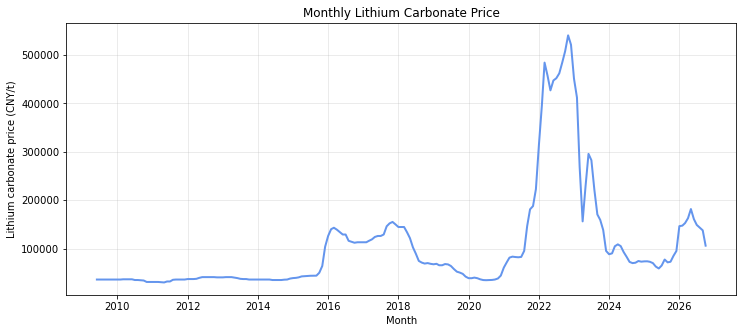

In [60]:
TARGET = "Selected lithium carbonate price (CNY/t)"

plt.figure(figsize=(12, 5))
plt.plot(df["Month"], df[TARGET], color="cornflowerblue", linewidth=2)
plt.xlabel("Month")
plt.ylabel("Lithium carbonate price (CNY/t)")
plt.title("Monthly Lithium Carbonate Price")
plt.grid(alpha=0.3)
plt.show()

In [61]:
variables = [
    TARGET,
    "Albemarle share price (USD/share)",
    "LME copper price (USD/metric tonne)",
    "LME cobalt cash price (USD/metric tonne) - updated Datastream",
    "CNY/USD exchange-rate series (source quote)"
]

# Check availability of selected variables
print(df[variables].notna().sum())

Selected lithium carbonate price (CNY/t)                         209
Albemarle share price (USD/share)                                 90
LME copper price (USD/metric tonne)                               90
LME cobalt cash price (USD/metric tonne) - updated Datastream    197
CNY/USD exchange-rate series (source quote)                       90
dtype: int64


In [62]:
model_data = pd.DataFrame()

model_data["Month"] = df["Month"]
model_data["TargetDate"] = df["Month"].shift(-1)
model_data["LithiumPrice_next_month"] = df[TARGET].shift(-1)

for variable in variables:
    if variable == TARGET:
        model_data["LithiumPrice_current"] = df[variable]
    else:
        model_data[variable] = df[variable]

model_data = model_data.dropna().reset_index(drop=True)

print("Modeling dataset shape:", model_data.shape)
print("Forecast dates:", model_data["TargetDate"].min(), "to", model_data["TargetDate"].max())
model_data.head()

Modeling dataset shape: (89, 8)
Forecast dates: 2019-06-01 00:00:00 to 2026-10-01 00:00:00


,Month,TargetDate,LithiumPrice_next_month,LithiumPrice_current,Albemarle share price (USD/share),LME copper price (USD/metric tonne),LME cobalt cash price (USD/metric tonne) - updated Datastream,CNY/USD exchange-rate series (source quote)
0,2019-05-01,2019-06-01,67250.0,68000.0,70.0040,6108.00,34500.0,6.851640
1,2019-06-01,2019-07-01,64000.0,67250.0,70.0575,5823.00,28000.0,6.890075
2,2019-07-01,2019-08-01,57700.0,64000.0,72.4325,5928.75,26650.0,6.873600
3,2019-08-01,2019-09-01,52250.0,57700.0,65.6900,5715.75,31008.0,7.041180
4,2019-09-01,2019-10-01,50400.0,52250.0,66.9325,5803.25,35975.5,7.114250


In [63]:
X_names = [
    "LithiumPrice_current",
    "Albemarle share price (USD/share)",
    "LME copper price (USD/metric tonne)",
    "LME cobalt cash price (USD/metric tonne) - updated Datastream",
    "CNY/USD exchange-rate series (source quote)"
]

X = model_data[X_names]
y = model_data["LithiumPrice_next_month"]

print("Number of observations:", len(model_data))
print("Number of predictors:", len(X_names))
print("\\nPredictor summary:")
display(X.describe())

Number of observations: 89
Number of predictors: 5
\nPredictor summary:


,LithiumPrice_current,Albemarle share price (USD/share),LME copper price (USD/metric tonne),LME cobalt cash price (USD/metric tonne) - updated Datastream,CNY/USD exchange-rate series (source quote)
count,89.000000,89.000000,89.000000,89.000000,89.000000
mean,156597.764045,144.667447,8894.437303,41111.896067,6.920680
std,142779.157315,66.550107,2146.675946,14560.697045,0.290624
min,34650.000000,58.072500,4993.000000,21440.000000,6.339380
25%,67250.000000,86.534000,7915.750000,31008.000000,6.741320
50%,88275.000000,126.954000,8972.620000,34302.500000,6.993800
75%,181000.000000,197.320000,9787.510000,51514.000000,7.173475
max,540375.000000,289.170000,14294.250000,81900.000000,7.308400


In [64]:
split_index = int(0.8 * len(model_data))

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

dates_train = model_data["TargetDate"].iloc[:split_index]
dates_test = model_data["TargetDate"].iloc[split_index:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training period:", dates_train.min(), "to", dates_train.max())
print("Testing period:", dates_test.min(), "to", dates_test.max())

Training observations: 71
Testing observations: 18
Training period: 2019-06-01 00:00:00 to 2025-04-01 00:00:00
Testing period: 2025-05-01 00:00:00 to 2026-10-01 00:00:00


In [65]:
model = linear_model.LinearRegression()
model.fit(X_train, y_train)

print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [ 8.02771441e-01  1.51425973e+02 -6.45470914e-01  1.88069273e+00
  2.17785552e+04]
Intercept: -209796.55342991525


In [66]:
y_predict_lr = model.predict(X_test)

print("Mean squared error: %.2f" % mean_squared_error(y_test, y_predict_lr))
print("Root mean squared error: %.2f" % np.sqrt(mean_squared_error(y_test, y_predict_lr)))
print("r2_score: %.2f" % r2_score(y_test, y_predict_lr))

Mean squared error: 539135753.40
Root mean squared error: 23219.30
r2_score: 0.67


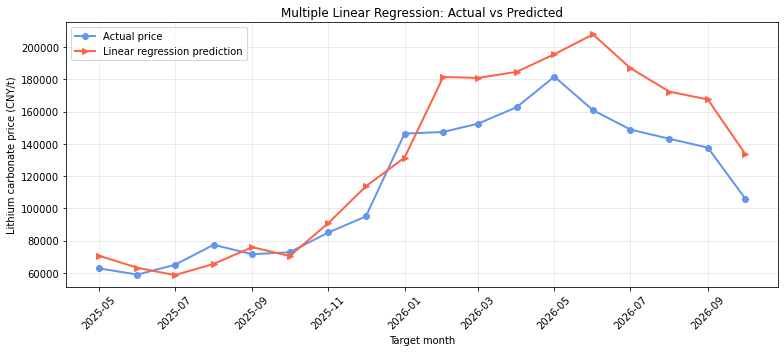

In [67]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(dates_test, y_test.values, marker="o", color="cornflowerblue",
        linewidth=2, label="Actual price")
ax.plot(dates_test, y_predict_lr, marker=">", color="tomato",
        linewidth=2, label="Linear regression prediction")

ax.set_xlabel("Target month")
ax.set_ylabel("Lithium carbonate price (CNY/t)")
ax.set_title("Multiple Linear Regression: Actual vs Predicted")
ax.legend()
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

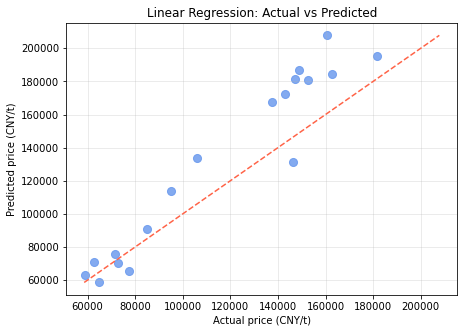

In [68]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_predict_lr, s=65, color="cornflowerblue", alpha=0.8)
lims = [
    min(y_test.min(), y_predict_lr.min()),
    max(y_test.max(), y_predict_lr.max())
]
plt.plot(lims, lims, "--", color="tomato")
plt.xlabel("Actual price (CNY/t)")
plt.ylabel("Predicted price (CNY/t)")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(alpha=0.3)
plt.show()

In [69]:
# Scale predictors using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [70]:
# Define the Gaussian Process kernel
kernel = ConstantKernel(1.0) * RBF(length_scale=np.ones(X_train.shape[1])) + WhiteKernel()

gp = GaussianProcessRegressor(
    kernel=kernel,
    n_restarts_optimizer=5,
    normalize_y=True,
    random_state=0
)

gp.fit(X_train_scaled, y_train)
print("Optimized kernel:", gp.kernel_)

Optimized kernel: 0.967**2 * RBF(length_scale=[0.202, 5.47, 4.14, 6.91, 1.72]) + WhiteKernel(noise_level=7.04e-05)


In [71]:
mu_gp, sd_gp = gp.predict(X_test_scaled, return_std=True)

print("Mean squared error: %.2f" % mean_squared_error(y_test, mu_gp))
print("Root mean squared error: %.2f" % np.sqrt(mean_squared_error(y_test, mu_gp)))
print("r2_score: %.2f" % r2_score(y_test, mu_gp))

Mean squared error: 4644729052.26
Root mean squared error: 68152.25
r2_score: -1.83


In [72]:
# 95% predictive interval
lower_gp = mu_gp - 1.96 * sd_gp
upper_gp = mu_gp + 1.96 * sd_gp

coverage = np.mean((y_test.values >= lower_gp) & (y_test.values <= upper_gp))
average_width = np.mean(upper_gp - lower_gp)

print("95%% interval coverage: %.1f%%" % (100 * coverage))
print("Average 95%% interval width: %.2f CNY/t" % average_width)

95% interval coverage: 77.8%
Average 95% interval width: 197730.35 CNY/t


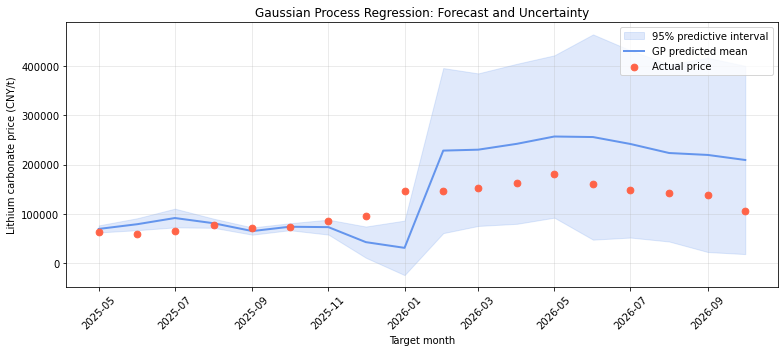

In [73]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.fill_between(
    dates_test,
    lower_gp,
    upper_gp,
    color="cornflowerblue",
    alpha=0.2,
    label="95% predictive interval"
)
ax.plot(dates_test, mu_gp, color="cornflowerblue", linewidth=2,
        label="GP predicted mean")
ax.scatter(dates_test, y_test, color="tomato", s=45,
           label="Actual price", zorder=3)

ax.set_xlabel("Target month")
ax.set_ylabel("Lithium carbonate price (CNY/t)")
ax.set_title("Gaussian Process Regression: Forecast and Uncertainty")
ax.legend()
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [74]:
comparison = pd.DataFrame({
    "Model": ["Multiple Linear Regression", "Gaussian Process Regression"],
    "MSE": [
        mean_squared_error(y_test, y_predict_lr),
        mean_squared_error(y_test, mu_gp)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_predict_lr)),
        np.sqrt(mean_squared_error(y_test, mu_gp))
    ],
    "R2": [
        r2_score(y_test, y_predict_lr),
        r2_score(y_test, mu_gp)
    ]
})

comparison

,Model,MSE,RMSE,R2
0,Multiple Linear Regression,5.391358e+08,23219.297005,0.671709
1,Gaussian Process Regression,4.644729e+09,68152.249062,-1.828269


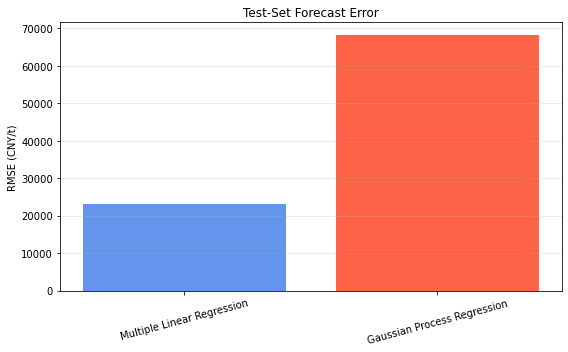

In [75]:
plt.figure(figsize=(8, 5))
plt.bar(comparison["Model"], comparison["RMSE"], color=["cornflowerblue", "tomato"])
plt.ylabel("RMSE (CNY/t)")
plt.title("Test-Set Forecast Error")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [76]:
errors = pd.DataFrame({
    "TargetDate": dates_test.values,
    "Actual": y_test.values,
    "LinearRegression": y_predict_lr,
    "GaussianProcess": mu_gp,
    "LinearRegressionError": y_test.values - y_predict_lr,
    "GaussianProcessError": y_test.values - mu_gp
})

errors

,TargetDate,Actual,LinearRegression,GaussianProcess,LinearRegressionError,GaussianProcessError
0,2025-05-01,62740.0,70654.654391,69398.129295,-7914.654391,-6658.129295
1,2025-06-01,58875.0,63061.515134,79045.370092,-4186.515134,-20170.370092
2,2025-07-01,64940.0,58561.989026,91529.628197,6378.010974,-26589.628197
3,2025-08-01,77337.5,65478.236335,80956.741689,11859.263665,-3619.241689
4,2025-09-01,71500.0,75896.915950,65042.850772,-4396.915950,6457.149228
5,2025-10-01,72740.0,70366.938564,73846.332287,2373.061436,-1106.332287
6,2025-11-01,84987.5,90879.421496,73040.568815,-5891.921496,11946.931185
7,2025-12-01,94937.5,113594.629820,42581.917281,-18657.129820,52355.582719
8,2026-01-01,146300.0,131424.593665,30977.575766,14875.406335,115322.424234
9,2026-02-01,147312.5,181447.656119,228417.775173,-34135.156119,-81105.275173


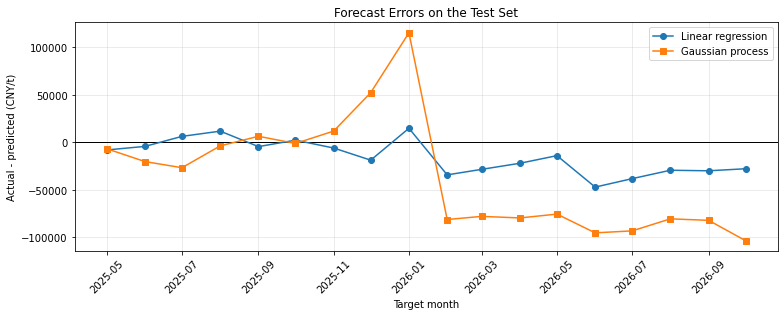

In [77]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axhline(0, color="black", linewidth=1)
ax.plot(errors["TargetDate"], errors["LinearRegressionError"],
        marker="o", label="Linear regression")
ax.plot(errors["TargetDate"], errors["GaussianProcessError"],
        marker="s", label="Gaussian process")
ax.set_xlabel("Target month")
ax.set_ylabel("Actual - predicted (CNY/t)")
ax.set_title("Forecast Errors on the Test Set")
ax.legend()
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [78]:
# Refit scaler and GPR using all available historical training pairs
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X)

gp_all = GaussianProcessRegressor(
    kernel=kernel,
    n_restarts_optimizer=5,
    normalize_y=True,
    random_state=0
)
gp_all.fit(X_all_scaled, y)

# Use the latest observed month's predictors to forecast the following month.
latest = df.iloc[[-1]]
X_next = pd.DataFrame({
    "LithiumPrice_current": latest[TARGET].values,
    "Albemarle share price (USD/share)": latest["Albemarle share price (USD/share)"].values,
    "LME copper price (USD/metric tonne)": latest["LME copper price (USD/metric tonne)"].values,
    "LME cobalt cash price (USD/metric tonne) - updated Datastream": latest["LME cobalt cash price (USD/metric tonne) - updated Datastream"].values,
    "CNY/USD exchange-rate series (source quote)": latest["CNY/USD exchange-rate series (source quote)"].values
})

X_next_scaled = scaler_all.transform(X_next)
forecast_mean, forecast_sd = gp_all.predict(X_next_scaled, return_std=True)

forecast_date = df["Month"].max() + pd.offsets.MonthBegin(1)

print("Latest predictor month:", df["Month"].max())
print("Forecast month:", forecast_date)
print("Forecast price: %.2f CNY/t" % forecast_mean[0])
print("95%% predictive interval: %.2f to %.2f CNY/t" %
      (forecast_mean[0] - 1.96*forecast_sd[0],
       forecast_mean[0] + 1.96*forecast_sd[0]))

Latest predictor month: 2026-10-01 00:00:00
Forecast month: 2026-11-01 00:00:00
Forecast price: 166474.52 CNY/t
95% predictive interval: 51835.07 to 281113.97 CNY/t


AVAILABLE OBSERVATIONS BY VARIABLE
-----------------------------------
Selected lithium carbonate price (CNY/t): 209 observations
Lithium carbonate price (CNY/metric tonne): 90 observations
China spot lithium carbonate price (CNY/t) - CSV: 186 observations
Albemarle share price (USD/share): 90 observations
SQM share price (USD/ADR): 90 observations
Tesla share price (USD/share): 90 observations
LME nickel price (USD/metric tonne): 90 observations
LME copper price (USD/metric tonne): 90 observations
LME lithium hydroxide price (USD/metric tonne): 63 observations
China GDP (100 million CNY, constant 2025 prices): 90 observations
US GDP (USD billion, current prices): 90 observations
CNY/USD exchange-rate series (source quote): 90 observations
China industrial production index (prior year = 100): 82 observations
US CPI (1982–84 = 100): 89 observations
China pure EV sales (units): 90 observations
China lithium-ion battery production (source units): 59 observations
Japan lithium battery inve

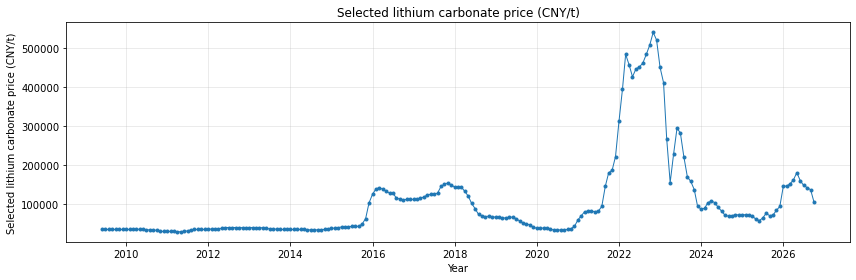

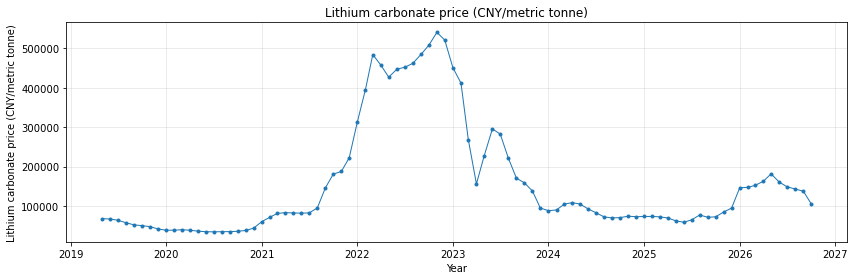

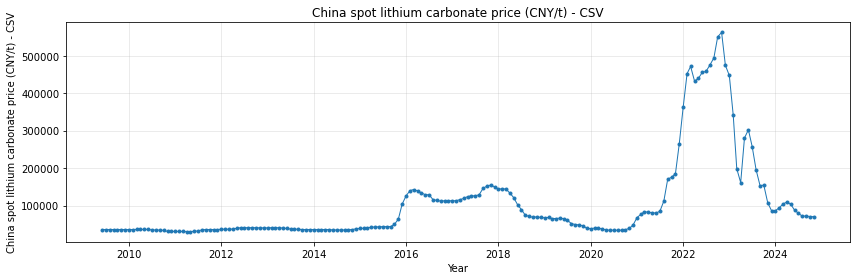

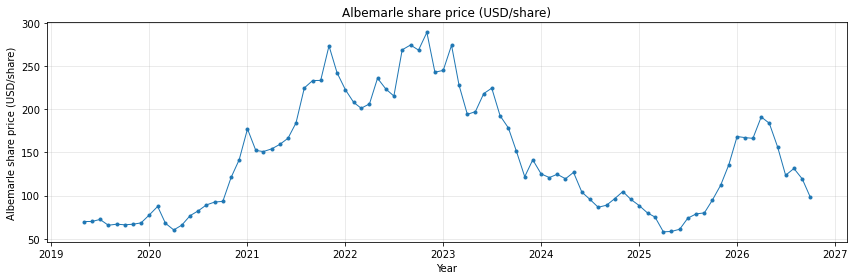

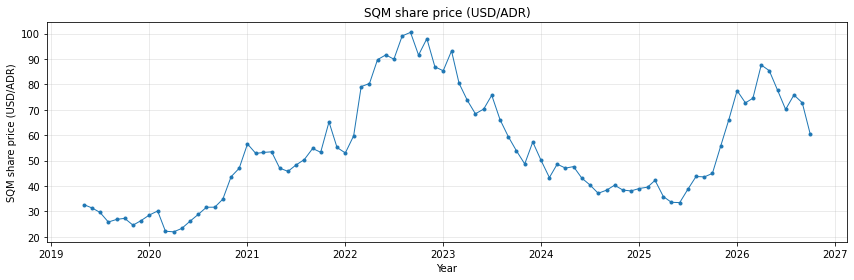

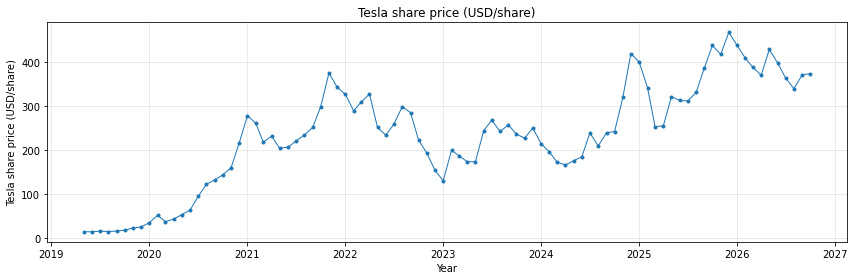

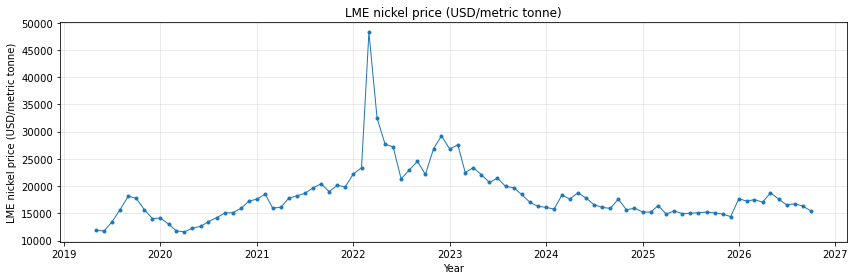

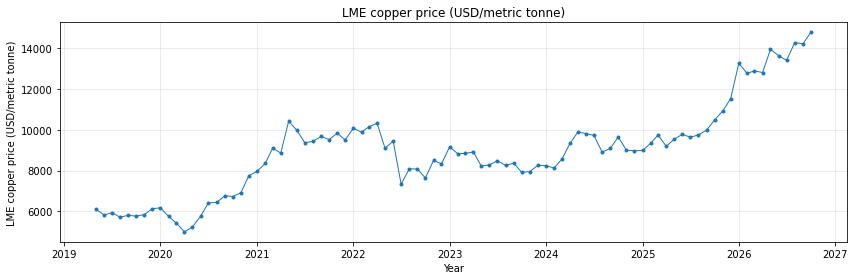

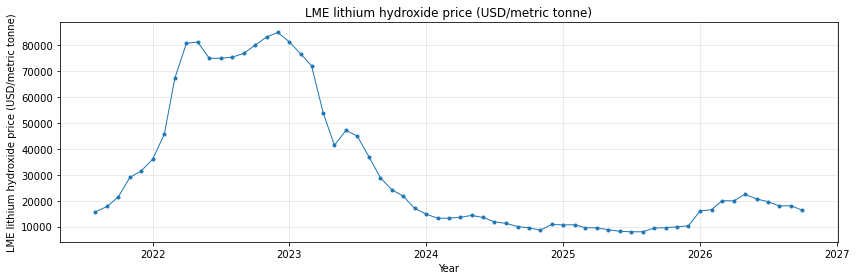

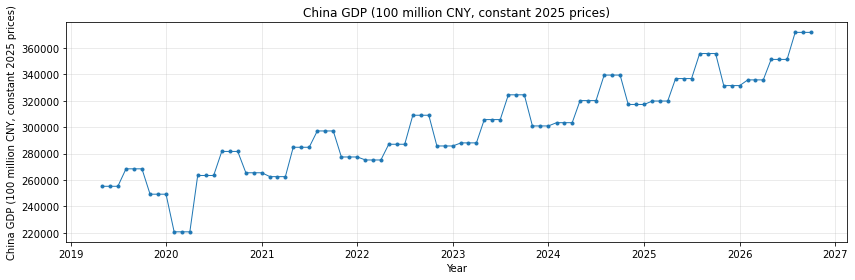

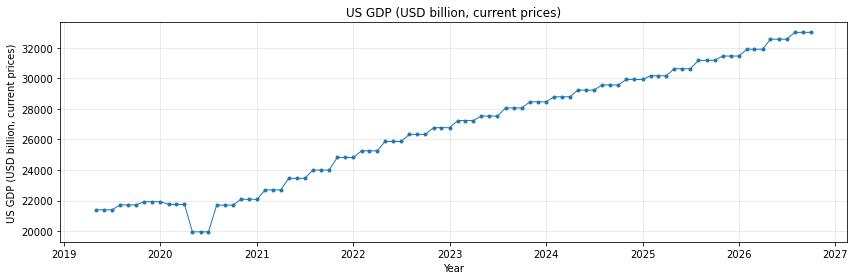

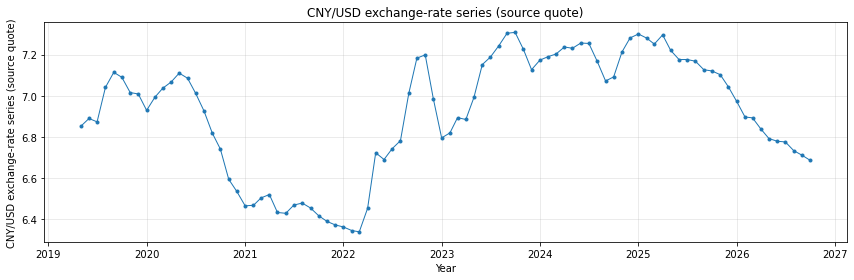

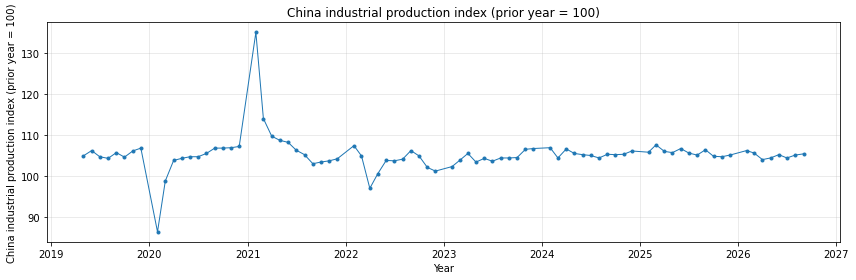

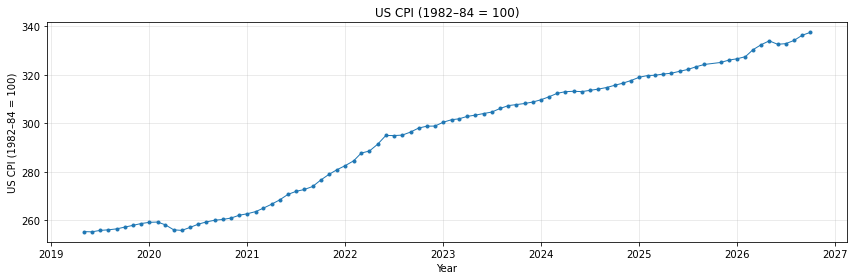

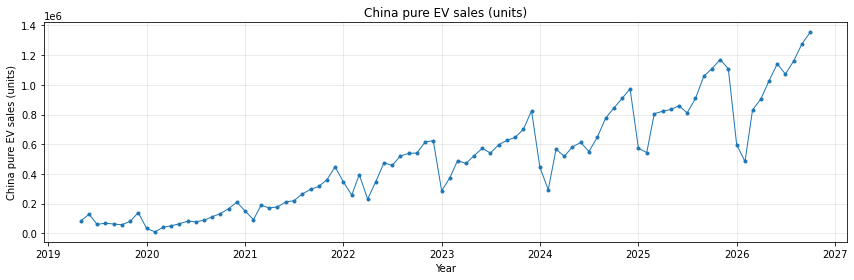

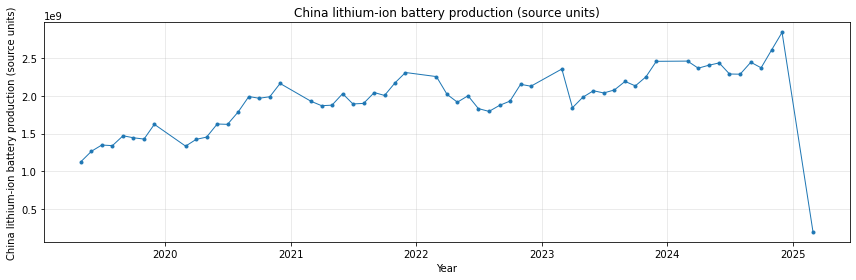

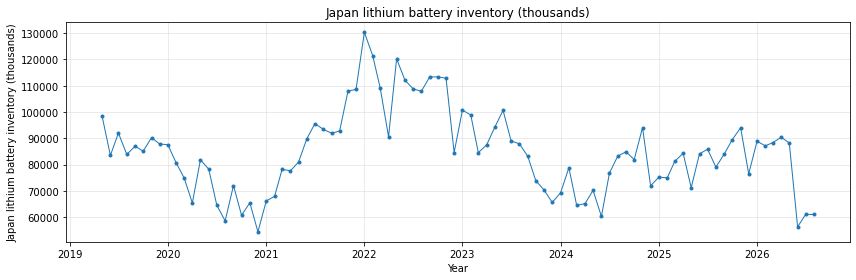

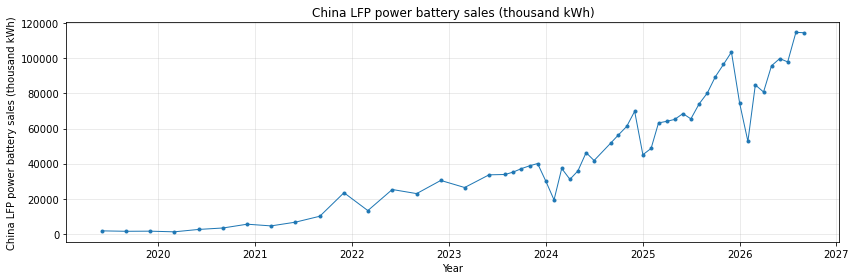

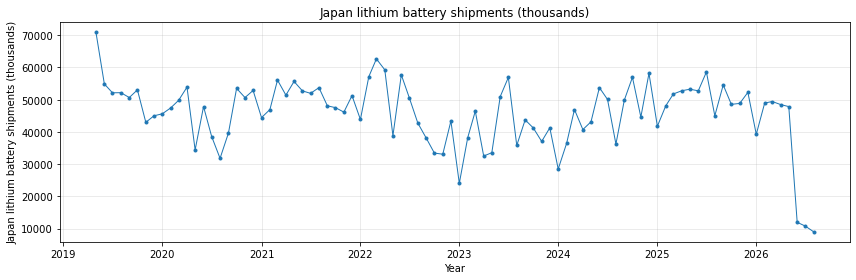

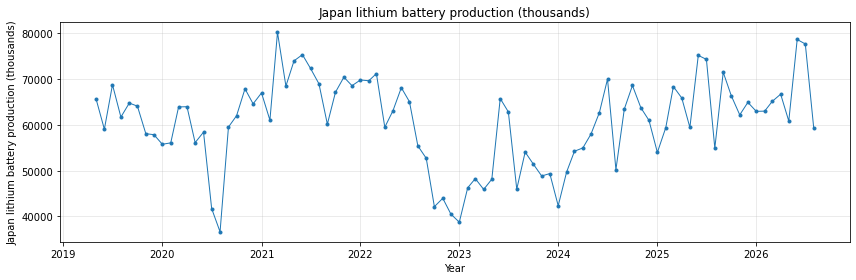

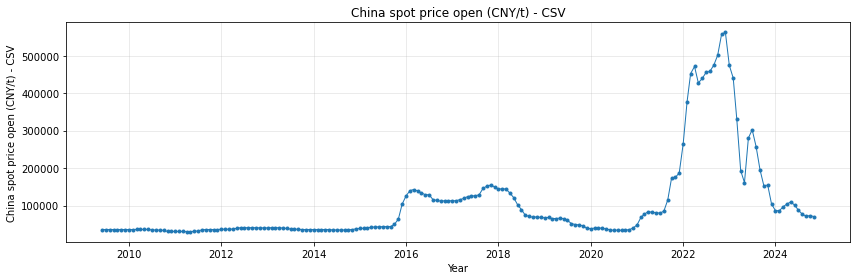

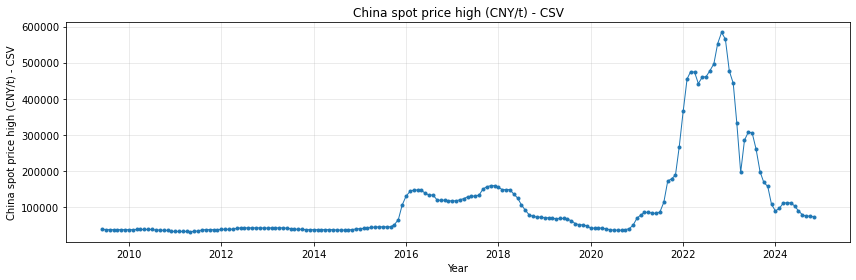

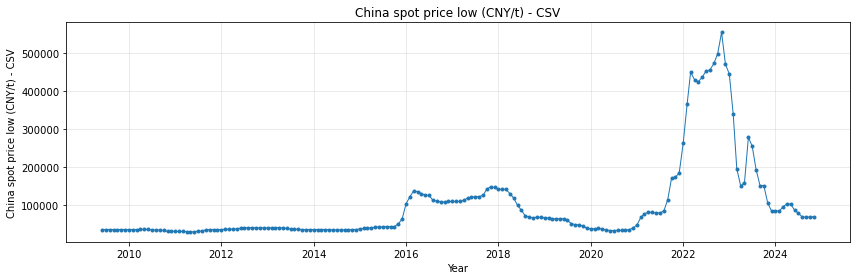

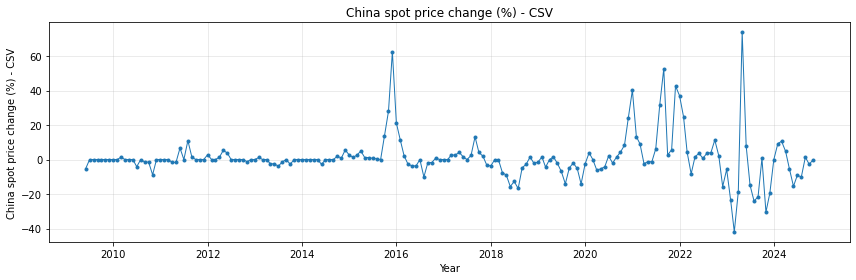

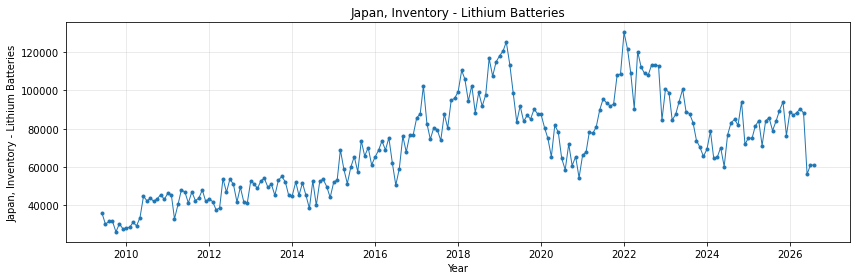

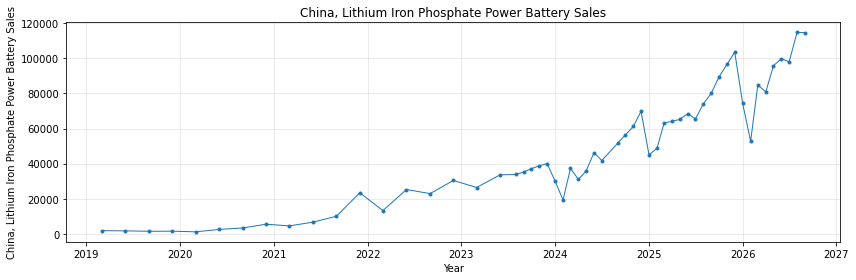

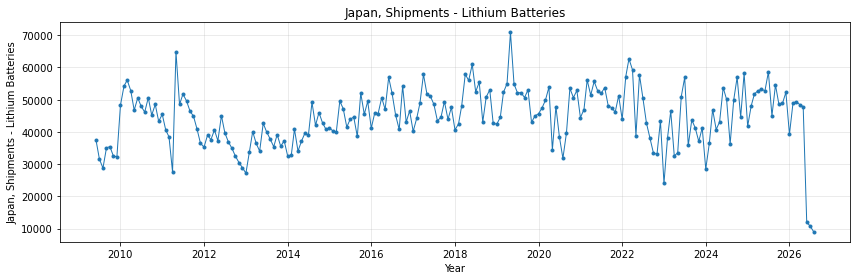

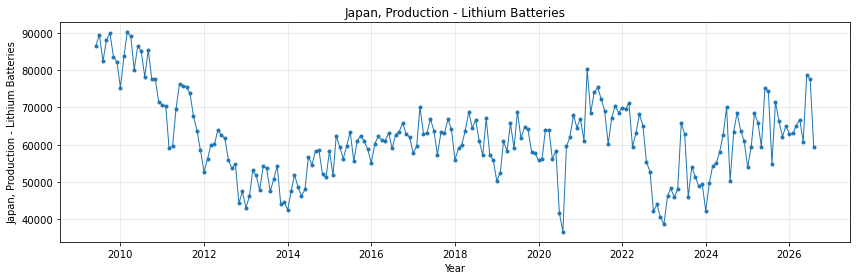

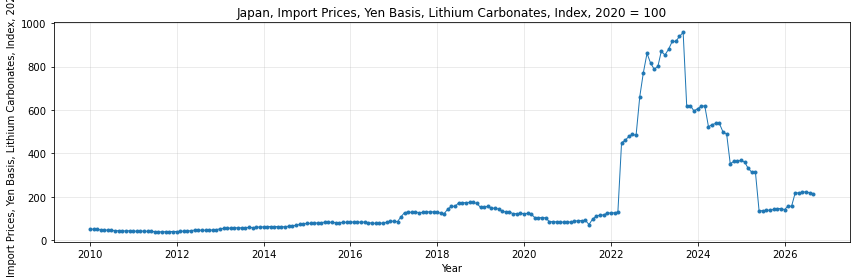

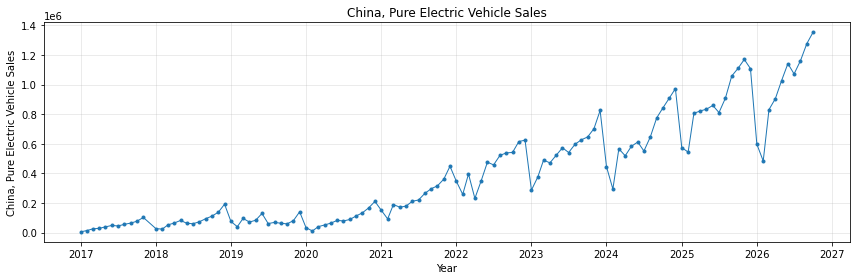

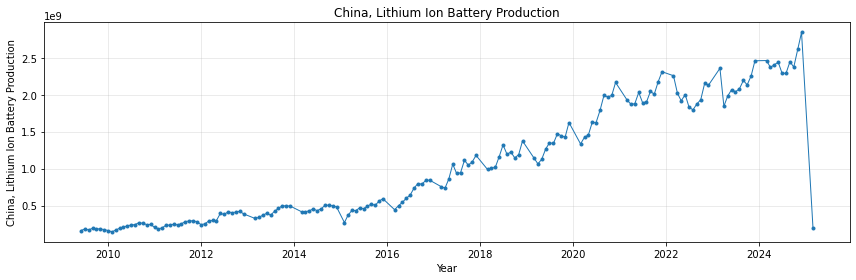

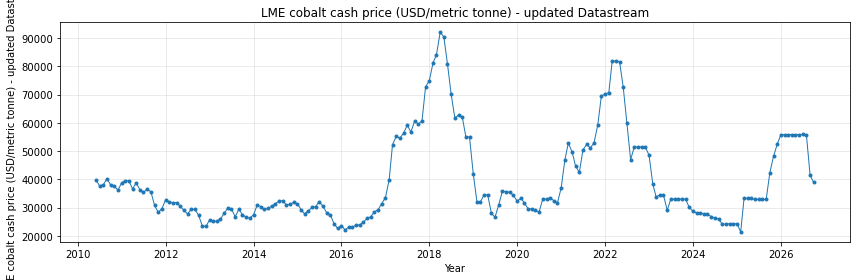

In [82]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the consolidated dataset
df = pd.read_csv("lithium_data_consolidated.csv")

# Convert Month to datetime
df["Month"] = pd.to_datetime(df["Month"])

# Keep observations from 2006 onward
df = df[df["Month"] >= "2006-01-01"].copy()

# Remove columns that are not actual numerical variables
exclude_columns = [
    "index",
    "Selected target source",
    "OLD - faulty cobalt settlement series (constant; excluded)"
]

# Select numerical columns, excluding the faulty cobalt series
plot_columns = [
    col for col in df.select_dtypes(include="number").columns
    if col not in exclude_columns
]

# Print number of available observations for each variable
print("AVAILABLE OBSERVATIONS BY VARIABLE")
print("-----------------------------------")

for col in plot_columns:
    print(f"{col}: {df[col].notna().sum()} observations")

# Plot every variable separately
for col in plot_columns:

    # Only remove missing values from THIS variable
    plot_data = df[["Month", col]].dropna()

    if len(plot_data) == 0:
        continue

    plt.figure(figsize=(12, 4))

    plt.plot(
        plot_data["Month"],
        plot_data[col],
        marker=".",
        linewidth=1
    )

    plt.title(col)
    plt.xlabel("Year")
    plt.ylabel(col)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


Number of lithium carbonate price observations: 209
First observation: 2009-06-01 00:00:00
Last observation: 2026-10-01 00:00:00


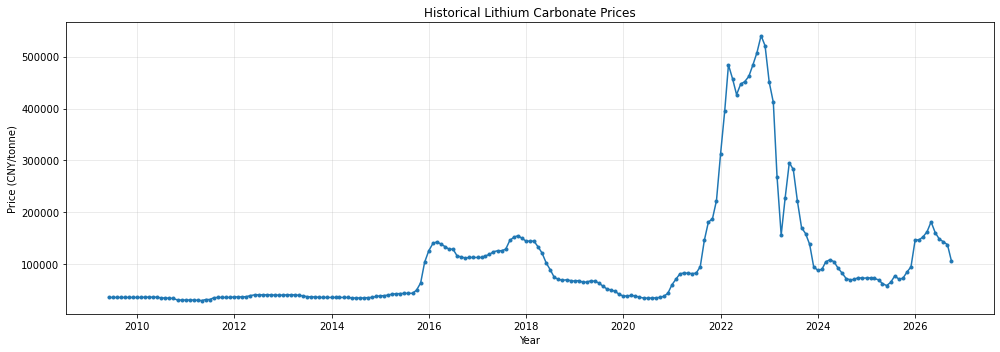

In [83]:

# Plot the complete lithium carbonate price series

price_column = "Selected lithium carbonate price (CNY/t)"

lithium_prices = df[["Month", price_column]].dropna()

print("Number of lithium carbonate price observations:",
      len(lithium_prices))

print("First observation:", lithium_prices["Month"].min())
print("Last observation:", lithium_prices["Month"].max())

plt.figure(figsize=(14, 5))

plt.plot(
    lithium_prices["Month"],
    lithium_prices[price_column],
    marker="o",
    markersize=3,
    linewidth=1.5
)

plt.title("Historical Lithium Carbonate Prices")
plt.xlabel("Year")
plt.ylabel("Price (CNY/tonne)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
